# 9. Auditoría de fuga de datos (2.5): «DataCo sin fuga»

El **momento de predicción** es la **creación del pedido**: el cliente acaba de comprar,
el modo de envío y los días prometidos ya están definidos, pero el pedido aún no se ha
despachado ni entregado. Se audita cada variable (original y derivada): disponibilidad en
ese momento, derivación del objetivo, identificadores y proxies, AUC univariado,
población de pedidos cancelados y entidades repetidas entre particiones.

DataCo es conocido por producir modelos de «retraso» con AUC ≈ 1: casi siempre se debe a
usar `Days for shipping (real)` o `Delivery Status`, que **son** el resultado. Este capítulo
lo demuestra y define la versión **sin fuga** que usa el resto del libro.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
train = load_train(include_canceled=True)
y = train[TARGET]
folds = temporal_folds(train[DATE_COL])

## 1. Disponibilidad de cada variable al momento de predicción

In [2]:
POSTERIOR = {
    "days_shipping_real": "Se conoce cuando el pedido se envía/entrega; el objetivo es días reales > programados.",
    "delivery_status": "Estado final de la entrega; «Late delivery» ES la etiqueta 1.",
    "order_status": "Estado del pedido en el sistema (COMPLETE, CLOSED, CANCELED, SUSPECTED_FRAUD...); se actualiza después de la compra.",
    "shipping_date": "Fecha de despacho = fecha del pedido + días reales; posterior y equivalente a days_shipping_real.",
}
def disponibilidad(c):
    if c == TARGET:
        return "No", "Variable objetivo."
    if c in POSTERIOR:
        return "No", POSTERIOR[c]
    if c in PII_COLS:
        return "Sí, pero excluida", "Dato personal o enmascarado; sin valor predictivo legítimo."
    if c in (ORDER_COL, ITEM_COL):
        return "Solo agrupar", "Identificador; correlaciona con el tiempo (es secuencial) y no describe el pedido."
    if c in (CUSTOMER_COL, "order_customer_id"):
        return "Solo agrupar", "Identificador del cliente (entidad); usarlo como predictor memorizaría clientes."
    if c in ID_COLS:
        return "Sí, como código", "Identificador numérico de una categoría ya presente como texto (redundante)."
    if c == DATE_COL:
        return "Sí", "Marca temporal del pedido; se usa para la partición y para derivar calendario."
    if c in ("benefit_per_order", "order_profit_per_order", "order_item_profit_ratio"):
        return "Sí, con cautela", "Ganancia calculada con precio, descuento y costo del producto; en DataCo se registra con la venta."
    if c == "days_shipping_scheduled":
        return "Sí", "Promesa de entrega definida por el modo de envío al comprar."
    if c in ("items_in_order", "orders_prev_7d") or c.startswith("order_") and c.endswith(("_sin", "_cos")) or c in ("order_year", "order_month", "order_dow", "order_hour", "order_weekend"):
        return "Sí", "Derivada del momento de la compra o del pasado (ventana cerrada a la izquierda)."
    return "Sí", "Atributo del pedido, producto, cliente o destino conocido al comprar."

cols = [c for c in train.columns if not c.endswith(("_sin", "_cos"))]
disp = pd.DataFrame([(c, *disponibilidad(c)) for c in cols], columns=["variable", "disponible_al_predecir", "evidencia"])
display(disp[disp["disponible_al_predecir"] != "Sí"])

,variable,disponible_al_predecir,evidencia
1,days_shipping_real,No,Se conoce cuando el pedido se envía/entrega; el objetivo es días r...
3,benefit_per_order,"Sí, con cautela","Ganancia calculada con precio, descuento y costo del producto; en ..."
5,delivery_status,No,Estado final de la entrega; «Late delivery» ES la etiqueta 1.
6,late_delivery_risk,No,Variable objetivo.
7,category_id,"Sí, como código",Identificador numérico de una categoría ya presente como texto (re...
11,customer_email,"Sí, pero excluida",Dato personal o enmascarado; sin valor predictivo legítimo.
12,customer_fname,"Sí, pero excluida",Dato personal o enmascarado; sin valor predictivo legítimo.
13,customer_id,Solo agrupar,Identificador del cliente (entidad); usarlo como predictor memoriz...
14,customer_lname,"Sí, pero excluida",Dato personal o enmascarado; sin valor predictivo legítimo.
15,customer_password,"Sí, pero excluida",Dato personal o enmascarado; sin valor predictivo legítimo.


## 2. Variables derivadas del objetivo y AUC univariado

AUC univariado de **todas** las variables, incluidas las sospechosas. Valores cercanos a 1
son señal de alerta. Las categóricas se codifican fuera de pliegue (temporal).

,variable,tipo,AUC univariado,alerta
0,delivery_status,categórica,1.0000,"ALERTA (>0,90)"
1,retraso_real_menos_programado,numérica,0.9747,"ALERTA (>0,90)"
2,mode_x_daypart,categórica,0.7581,"revisar (>0,75)"
3,shipping_mode,categórica,0.7265,sin alerta
4,days_shipping_real,numérica,0.7098,sin alerta
5,horas_hasta_despacho,numérica,0.7084,sin alerta
6,days_shipping_scheduled,numérica,0.6978,sin alerta
7,order_status,categórica,0.5415,sin alerta
8,payment_type,categórica,0.5323,sin alerta
9,order_afternoon,numérica,0.5297,sin alerta


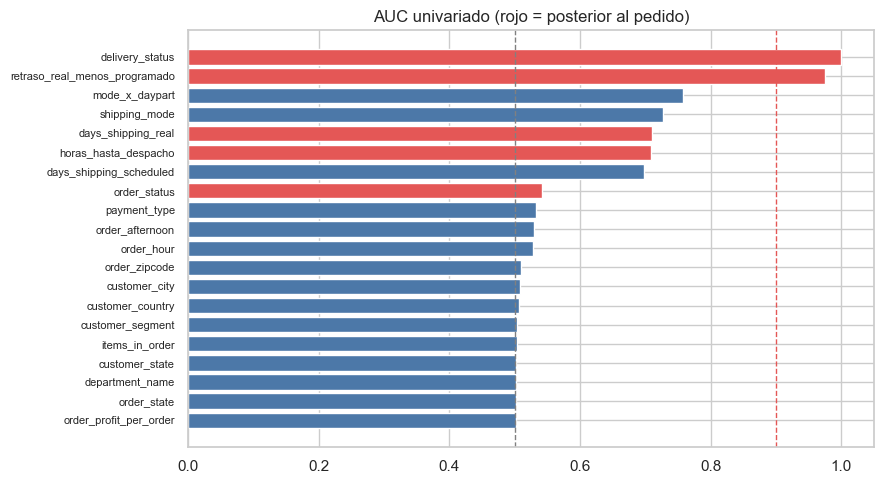

late_delivery_risk,0,1
delivery_status,,
Advance shipping,32954,0
Late delivery,0,78549
Shipping canceled,6032,0
Shipping on time,25540,0


In [3]:
train["retraso_real_menos_programado"] = train["days_shipping_real"] - train["days_shipping_scheduled"]
train["horas_hasta_despacho"] = (train["shipping_date"] - train[DATE_COL]).dt.total_seconds() / 3600
num_like = [c for c in cols + ["retraso_real_menos_programado", "horas_hasta_despacho"]
            if c not in (TARGET, DATE_COL, "shipping_date") and pd.api.types.is_numeric_dtype(train[c]) and c not in PII_COLS]
cat_like = [c for c in cols if c not in num_like + [TARGET, DATE_COL, "shipping_date"] + PII_COLS
            and train[c].nunique() < 5000 and train[c].nunique() > 1]
filas = [{"variable": c, "tipo": "numérica", "AUC univariado": univariate_auc(train[c], y)} for c in num_like]
filas += [{"variable": c, "tipo": "categórica", "AUC univariado": categorical_auc_oof(train[c], y, folds)} for c in cat_like]
auc = pd.DataFrame(filas).dropna().sort_values("AUC univariado", ascending=False).reset_index(drop=True)
auc["alerta"] = np.select([auc["AUC univariado"] > 0.90, auc["AUC univariado"] > 0.75], ["ALERTA (>0,90)", "revisar (>0,75)"], "sin alerta")
auc.to_csv(TABLES / "auc_univariado_todas.csv", index=False)
display(auc.head(15).round(4))

fig, ax = plt.subplots(figsize=(9, 5))
top = auc.head(20).iloc[::-1]
ax.barh(top["variable"], top["AUC univariado"], color=np.where(top["variable"].isin(list(POSTERIOR) + ["retraso_real_menos_programado", "horas_hasta_despacho"]), "#e45756", "#4c78a8"))
ax.axvline(0.9, color="#e45756", ls="--", lw=1); ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_title("AUC univariado (rojo = posterior al pedido)"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); save_figure(fig, "09_auc_univariado.png"); plt.show()
display(pd.crosstab(train["delivery_status"], y))

**Interpretación.** `delivery_status` separa perfectamente (AUC = 1): es la etiqueta con
otro nombre. La diferencia `días reales − programados` reproduce la regla que define el
objetivo (AUC ≈ 0,97). **Lección importante:** `days_shipping_real` **sola** tiene un AUC de
≈ 0,71, parecido al del modo de envío, y no dispararía la alerta univariada; la fuga aparece al
**combinarla** con los días programados. Por eso la auditoría no se basa solo en el AUC, sino
en la **disponibilidad temporal** de cada variable. `order_status` también es posterior y
delata cancelaciones. **Todas se excluyen.** `days_shipping_scheduled`
y `shipping_mode` tienen AUC ≈ 0,7, alto pero legítimo: la promesa de entrega se conoce al
comprar. Los identificadores secuenciales (`order_id`, `order_item_id`) tienen AUC ≈ 0,5, pero
codifican el tiempo y no describen el pedido: se excluyen.

## 3. Demostración: DataCo **con fuga** vs **sin fuga**

Misma regresión logística, mismos pliegues temporales con *gap*. Solo cambia si se
incluyen variables posteriores al pedido.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
def lr(num, cat):
    return Pipeline([("prep", ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore"), cat)])),
                     ("clf", LogisticRegression(max_iter=2000))])
escenarios = {
    "Con fuga: días reales + modo de envío": (["days_shipping_real", "days_shipping_scheduled"], ["shipping_mode"]),
    "Con fuga: estado del pedido + modo de envío": ([], ["order_status", "shipping_mode"]),
    "Sin fuga: solo modo de envío": ([], ["shipping_mode"]),
}
res = []
for nombre, (num, cat) in escenarios.items():
    s = cross_val_score(lr(num, cat), train[num + cat], y, cv=folds, scoring="roc_auc", n_jobs=1)
    res.append({"escenario": nombre, "ROC-AUC media (CV temporal)": s.mean(), "desv. est.": s.std()})
con_sin = pd.DataFrame(res)
con_sin.to_csv(TABLES / "con_fuga_vs_sin_fuga.csv", index=False)
display(con_sin.round(4))

,escenario,ROC-AUC media (CV temporal),desv. est.
0,Con fuga: días reales + modo de envío,0.9748,0.0024
1,Con fuga: estado del pedido + modo de envío,0.7617,0.0021
2,Sin fuga: solo modo de envío,0.7273,0.0027


**Interpretación.** Con los días reales el modelo alcanza un ROC-AUC casi perfecto: no
predice, **lee la respuesta** (no llega a 1 solo porque los cancelados tienen etiqueta 0). Con el estado del pedido mejora sobre el modo de
envío porque detecta las cancelaciones. Sin fuga, el modo de envío solo da un AUC ≈ 0,73.
Ese es el techo realista contra el que se compara el modelo base.

### ¿Cómo se genera la etiqueta? El techo sin fuga

Las variables con fuga no entran al modelo, pero sí sirven para **entender** el mecanismo
que genera la etiqueta. Se cruza, para los pedidos despachados, el modo de envío con los días
reales y la jornada del pedido.

In [5]:
desp = train[train["delivery_status"] != "Shipping canceled"]
dist_real = pd.crosstab(desp["shipping_mode"], desp["days_shipping_real"], normalize="index").round(3)
dist_real["días programados"] = desp.groupby("shipping_mode")["days_shipping_scheduled"].first()
display(dist_real)
celda = desp.groupby("mode_x_daypart")[TARGET].agg(["mean", "size"]).rename(columns={"mean": "P(tardía)", "size": "líneas"})
display(celda.round(3))
p_bayes = desp["mode_x_daypart"].map(celda["P(tardía)"])
techo = pd.DataFrame([{"referencia": "Techo sin fuga (tasa por modo × jornada, en entrenamiento)",
                       "ROC-AUC": roc_auc_score(desp[TARGET], p_bayes),
                       "Accuracy": float(((p_bayes >= 0.5).astype(int) == desp[TARGET]).mean())}])
techo.to_csv(TABLES / "techo_sin_fuga.csv", index=False)
display(techo.round(4))

days_shipping_real,0,1,2,3,4,5,6,días programados
shipping_mode,,,,,,,,
First Class,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1
Same Day,0.531,0.469,0.000,0.000,0.000,0.000,0.000,0
Second Class,0.000,0.000,0.202,0.200,0.199,0.201,0.199,2
Standard Class,0.000,0.000,0.202,0.201,0.198,0.195,0.203,4


,P(tardía),líneas
mode_x_daypart,,
First Class | AM,1.000,10056
First Class | PM,1.000,10986
Same Day | AM,0.000,3911
Same Day | PM,1.000,3456
Second Class | AM,0.797,13600
Second Class | PM,0.800,13283
Standard Class | AM,0.396,41003
Standard Class | PM,0.401,40748


,referencia,ROC-AUC,Accuracy
0,"Techo sin fuga (tasa por modo × jornada, en entrenamiento)",0.7754,0.7227


**Interpretación: el dataset es simulado con reglas simples.**

- **Standard Class** promete 4 días y los días reales son **uniformes entre 2 y 6** → tarde con
  probabilidad 2/5 = 40 %, **al azar**.
- **Second Class** promete 2 días y los reales son uniformes entre 2 y 6 → tarde 4/5 = 80 %.
- **First Class** promete 1 día y tarda **siempre 2** → tarde el 100 %.
- **Same Day** promete 0 días: tarda 0 si se pide antes del mediodía y 1 si se pide después →
  la jornada lo determina.

Con la información disponible al crear el pedido, lo mejor que se puede hacer es asignar esas
probabilidades: el **techo sin fuga es ROC-AUC ≈ 0,77 y accuracy ≈ 0,73**. Dentro de Standard y
Second Class el resultado es **aleatorio**: ninguna variable del pedido, del cliente o del
destino puede explicarlo, y por eso todas tienen AUC ≈ 0,5. Cualquier modelo que supere
claramente este techo está usando fuga.

## 4. Pedidos cancelados y sospechosos de fraude

Un pedido cancelado o sospechoso de fraude **nunca se entrega**, así que su etiqueta es 0
por definición (no «llegó a tiempo»). Mezclarlos con entregas reales cambia la pregunta y
convierte a variables asociadas con el fraude (por ejemplo, el medio de pago) en proxies de
la cancelación. **Criterio fijado antes de mirar el resultado:** excluir de la población de
modelado los estados de entrega cuya tasa de retraso sea < 2 %.

In [6]:
canc = train["delivery_status"] == "Shipping canceled"
tabla = train.groupby("delivery_status")[TARGET].agg(["size", "mean"]).rename(columns={"size": "líneas", "mean": "tasa_tardía"})
display(tabla.round(4))
display(pd.crosstab(train["payment_type"], train["order_status"].where(train["order_status"].isin(["CANCELED", "SUSPECTED_FRAUD"]), "resto"), normalize="index").round(4))
auc_pago_todo = categorical_auc_oof(train["payment_type"], y, folds)
tr_ok = train[~canc].reset_index(drop=True)
auc_pago_desp = categorical_auc_oof(tr_ok["payment_type"], tr_ok[TARGET], temporal_folds(tr_ok[DATE_COL]))
rate_c = float(y[canc].mean())
excluir = bool(canc.any() and rate_c < 0.02)
decision = pd.DataFrame([{"excluir_cancelados": excluir, "estado": "Shipping canceled (CANCELED + SUSPECTED_FRAUD)",
                          "n_excluidos_train": int(canc.sum()), "pct_excluidos": 100 * canc.mean(),
                          "tasa_tardia_cancelados": rate_c, "tasa_tardia_resto": float(y[~canc].mean()),
                          "criterio": "excluir si la tasa de retraso del estado es < 2 % (no entregados)"}])
decision.to_csv(TABLES / "decision_poblacion.csv", index=False)
md_out(f"Líneas canceladas/fraude en entrenamiento: **{es(int(canc.sum()), 0)}** ({es(canc.mean(), 2, pct=True)}), tasa de retraso **{es(rate_c, 2, pct=True)}**.\n\n"
       f"AUC univariado de `payment_type`: **{es(auc_pago_todo, 3)}** con cancelados y **{es(auc_pago_desp, 3)}** solo con pedidos despachados. "
       "Toda su «señal» venía de que el fraude se concentra en transferencias.\n\n"
       + ("**Decisión:** se **excluyen** los pedidos cancelados y sospechosos de fraude de la población de modelado, en entrenamiento y prueba. "
          "La regla se basa en el estado de entrega (no en el resultado del modelo) y se aplica **después** de la partición. "
          "La pregunta del modelo queda: *dado que el pedido se despachará, ¿llegará tarde?* Los capítulos 10 y 11 leen esta decisión."
          if excluir else "**Decisión:** se conservan."))

,líneas,tasa_tardía
delivery_status,,
Advance shipping,32954,0.0
Late delivery,78549,1.0
Shipping canceled,6032,0.0
Shipping on time,25540,0.0


order_status,CANCELED,SUSPECTED_FRAUD,resto
payment_type,,,
CASH,0.0000,0.0000,1.0000
DEBIT,0.0000,0.0000,1.0000
PAYMENT,0.0000,0.0000,1.0000
TRANSFER,0.0735,0.0799,0.8466


Líneas canceladas/fraude en entrenamiento: **6.032** (4,22 %), tasa de retraso **0,00 %**.

AUC univariado de `payment_type`: **0,532** con cancelados y **0,504** solo con pedidos despachados. Toda su «señal» venía de que el fraude se concentra en transferencias.

**Decisión:** se **excluyen** los pedidos cancelados y sospechosos de fraude de la población de modelado, en entrenamiento y prueba. La regla se basa en el estado de entrega (no en el resultado del modelo) y se aplica **después** de la partición. La pregunta del modelo queda: *dado que el pedido se despachará, ¿llegará tarde?* Los capítulos 10 y 11 leen esta decisión.

## 5. Entidades repetidas y duplicados entre particiones

Se lee la prueba **solo** para comprobar identificadores y patrones (sin etiquetas ni
estadísticas que guíen decisiones).

In [7]:
test_full = load_test(include_canceled=True)
pred_cols = [c for c in RENAME.values() if c not in [TARGET, ITEM_COL, ORDER_COL, DATE_COL, "shipping_date"] + LEAKAGE_COLS]
h_tr = pd.util.hash_pandas_object(train[pred_cols], index=False)
h_te = pd.util.hash_pandas_object(test_full[pred_cols], index=False)
compartidos = set(h_tr) & set(h_te)
rng = np.random.default_rng(RANDOM_STATE)
perm = rng.permutation(len(train)); cut = int(0.8 * len(perm))
naive_share = train.iloc[perm[cut:]][ORDER_COL].isin(set(train.iloc[perm[:cut]][ORDER_COL])).mean()
dup = pd.DataFrame([
    {"comprobación": "pedidos en entrenamiento y prueba", "resultado": len(set(train[ORDER_COL]) & set(test_full[ORDER_COL]))},
    {"comprobación": "líneas (order_item_id) en ambos", "resultado": len(set(train[ITEM_COL]) & set(test_full[ITEM_COL]))},
    {"comprobación": "pedido más reciente de train vs más antiguo de test (días)", "resultado": (test_full[DATE_COL].min() - train[DATE_COL].max()).days},
    {"comprobación": "clientes con pedidos en ambos (esperado, no se usan como predictor)", "resultado": len(set(train[CUSTOMER_COL]) & set(test_full[CUSTOMER_COL]))},
    {"comprobación": "patrones de predictoras idénticos en ambos (sin ids)", "resultado": len(compartidos)},
    {"comprobación": "% de líneas de validación cuyo pedido estaría en train con partición ALEATORIA por filas", "resultado": round(100 * naive_share, 1)},
])
dup.to_csv(TABLES / "auditoria_duplicados.csv", index=False)
display(dup)

,comprobación,resultado
0,pedidos en entrenamiento y prueba,0.0
1,líneas (order_item_id) en ambos,0.0
2,pedido más reciente de train vs más antiguo de test (días),7.0
3,"clientes con pedidos en ambos (esperado, no se usan como predictor)",6426.0
4,patrones de predictoras idénticos en ambos (sin ids),0.0
5,% de líneas de validación cuyo pedido estaría en train con partici...,89.6


**Interpretación.** La partición cronológica no comparte pedidos ni líneas y deja 7 días
de separación. Una partición aleatoria por filas pondría en validación líneas cuyo pedido
(con la **misma etiqueta**) está en entrenamiento: eso inflaría las métricas. No hay filas con
patrones de predictoras idénticos entre entrenamiento y prueba: no hay fuga por duplicación.

## 6. Conclusión de la auditoría

In [8]:
final = disp.merge(auc[["variable", "AUC univariado"]], on="variable", how="left")
def decision_var(v):
    if v == TARGET: return "Objetivo"
    if v in POSTERIOR: return "Excluir: fuga (posterior al pedido)"
    if v in PII_COLS: return "Excluir: dato personal"
    if v in (ORDER_COL, ITEM_COL, CUSTOMER_COL, "order_customer_id"): return "Excluir: identificador (solo agrupar)"
    if v in ID_COLS: return "Excluir: código redundante"
    if v == DATE_COL: return "Usar solo para partición y calendario"
    if v in ("product_description", "product_status", "product_image", "order_zipcode"): return "Excluir: vacía, constante o redundante"
    if v in ("sales_per_customer", "order_item_total", "order_profit_per_order", "order_item_product_price", "product_price", "benefit_per_order",
             "order_item_discount", "days_shipping_scheduled", "customer_country", "customer_city", "customer_state",
             "order_city", "order_state", "product_name", "customer_zipcode", "order_year", "order_month", "order_dow", "order_hour"):
        return "Excluir: redundante o reemplazada (cap. 10)"
    return "Candidata (se decide en cap. 10)"
final["decisión"] = final["variable"].map(decision_var)
final["riesgo_de_fuga"] = np.select([final["variable"].isin(list(POSTERIOR) + [TARGET]), final["variable"].isin([ORDER_COL, ITEM_COL])],
                                    ["Alto", "Medio (codifica tiempo)"], "Bajo")
final.to_csv(TABLES / "auditoria_fuga.csv", index=False)
display(final[["variable", "disponible_al_predecir", "AUC univariado", "riesgo_de_fuga", "decisión"]].round(4))

,variable,disponible_al_predecir,AUC univariado,riesgo_de_fuga,decisión
0,payment_type,Sí,0.5323,Bajo,Candidata (se decide en cap. 10)
1,days_shipping_real,No,0.7098,Alto,Excluir: fuga (posterior al pedido)
2,days_shipping_scheduled,Sí,0.6978,Bajo,Excluir: redundante o reemplazada (cap. 10)
3,benefit_per_order,"Sí, con cautela",0.5019,Bajo,Excluir: redundante o reemplazada (cap. 10)
4,sales_per_customer,Sí,0.5009,Bajo,Excluir: redundante o reemplazada (cap. 10)
...,...,...,...,...,...
57,order_weekend,Sí,0.5016,Bajo,Candidata (se decide en cap. 10)
58,order_afternoon,Sí,0.5297,Bajo,Candidata (se decide en cap. 10)
59,mode_x_daypart,Sí,0.7581,Bajo,Candidata (se decide en cap. 10)
60,items_in_order,Sí,0.5030,Bajo,Candidata (se decide en cap. 10)


**Lista de variables descartadas o en observación.**

- **Descartadas por fuga:** `days_shipping_real`, `delivery_status`, `order_status`,
  `shipping_date` (y cualquier derivada de ellas).
- **Descartadas por ser identificadores o datos personales:** ids de pedido, línea, cliente,
  producto y categoría; nombre, apellido, correo, contraseña, calle y código postal.
- **Población:** se excluyen los pedidos **cancelados o sospechosos de fraude** (etiqueta 0 por
  construcción); `payment_type` deja de tener señal una vez excluidos.
- **En observación:** la ganancia (`order_item_profit_ratio`) se considera conocida al vender
  en DataCo, pero en una empresa real podría incluir ajustes posteriores; su AUC ≈ 0,50 descarta
  que sea un proxy. El destino (mercado/región/país) no es fuga, pero está confundido con el
  periodo (cap. 7–8).

Con esto, el resto del libro trabaja con **«DataCo (sin fuga)»** y su métrica principal,
**ROC-AUC**.